# Laplace approximation exploration

Visual walk-through of `bayes_cep.laplace`: the low-rank Laplace approximation of the posterior for the single retained patient (`example_data/raw/`, `example_data/preprocessing/`, `example_data/map/`). The posterior is approximated by $\mathcal N(m_\mathrm{MAP}, \Gamma)$ with the precision $\Gamma^{-1} = \Gamma_0^{-1} + H$, where $\Gamma_0$ is the prior covariance and $H = J^T B^T \Gamma_\mathrm{noise}^{-1} B J$ the Gauss-Newton Hessian of the data misfit at the MAP estimate (`GaussNewtonMisfitHessian`: one Jacobian-vector product, one likelihood Hessian-vector product and one adjoint solve). The dominant eigenpairs $(\lambda_i, v_i)$ of $H v = \lambda \Gamma_0^{-1} v$ give the low-rank form $\Gamma = \Gamma_0 - V D V^T$ with $D = \mathrm{diag}(\lambda_i / (1 + \lambda_i))$ (`ls_bayesian.lowrank.LowRankGaussian`): directions with $\lambda_i \gg 1$ are determined by the data, the others by the prior.

The approximation is centered at the MAP estimate of `pixi run example-map`, so it is only as good as that estimate (the example MAP run stops at its iteration limit). `pixi run example-laplace` runs the same computation non-interactively (`single_runs.laplace.LaplaceRun`) and writes its outputs to `example_data/laplace/`.

This notebook is for interactive/visual inspection only.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
import zarr
from ls_bayesian.lowrank.eigensolvers import RandomizedDoublePassSolver

from bayes_cep.laplace.builder import LaplaceBuilder, LaplaceSettings
from bayes_cep.mesh.geodesic import assemble_edge_length_graph, compute_graph_distances
from bayes_cep.mesh.interpolation import NearestNeighborInterpolationStrategy
from bayes_cep.mesh.io import load_pyvista_mesh
from bayes_cep.posterior.builder import PosteriorBuilder, PosteriorSettings
from bayes_cep.posterior.likelihood import LikelihoodSettings
from bayes_cep.statistics.axial_error_metrics import compute_error_by_distance
from bayes_cep.statistics.axial_statistics import (
    compute_axial_mean_and_variance,
    compute_standard_deviation_degrees,
)
from single_runs.data import PreprocessedData
from single_runs.reference import reference_eikonal_settings, reference_prior_parameters

pv.set_jupyter_backend("trame")

DATA_DIR = Path.cwd().parent / "example_data"
RAW_DIR = DATA_DIR / "raw"
PREPROCESSING_DIR = DATA_DIR / "preprocessing"
MAP_DIR = DATA_DIR / "map"
MCMC_DIR = DATA_DIR / "mcmc"

## Load preprocessed data and the MAP estimate

In [2]:
mesh = load_pyvista_mesh(RAW_DIR / "mesh.vtu")
basis_vectors = np.load(RAW_DIR / "basis_vecs.npy")
data = PreprocessedData.load(PREPROCESSING_DIR)
map_estimate = np.load(MAP_DIR / "map_estimate.npy")

interpolation_strategy = NearestNeighborInterpolationStrategy()
connectivity = mesh.cells.reshape(-1, 4)[:, 1:]

print(f"{mesh.n_points} vertices, {mesh.n_cells} triangles")
print(f"{data.observed_vertex_indices.shape[0]} observed vertices")

15820 vertices, 31375 triangles
1000 observed vertices


## Build the posterior components

Reference settings, matching `single_runs.reference.reference_laplace_config`. `PosteriorBuilder.build_components` returns the likelihood, the forward map and the prior without composing them into a `LogPosterior`: the Hessian needs the forward map and the likelihood itself.

In [3]:
posterior_settings = PosteriorSettings(
    mesh=mesh,
    basis_vectors=basis_vectors,
    prior_mean_vector=data.prior_mean,
    prior_parameters=reference_prior_parameters(),
    eikonal_settings=reference_eikonal_settings(),
    likelihood_settings=LikelihoodSettings(
        num_vertices=mesh.n_points,
        observed_vertex_indices=data.observed_vertex_indices,
        data_vector=data.observed_activation_times,
        noise_variance=data.noise_variance,
    ),
)
components = PosteriorBuilder(
    posterior_settings, interpolation_strategy=interpolation_strategy
).build_components()

## Compute the low-rank approximation

`NUM_EIGENVALUES` is the rank budget $k$; the randomized double-pass solver (Saibaba et al., 2016) needs $2(k + p)$ Hessian products for oversampling $p$, each one forward and one adjoint triangular solve, and symmetrizes its projected matrix, which tolerates the single precision of the eikonal solver. `LanczosSolver` is the alternative. Eigenpairs with an eigenvalue at most `MINIMUM_EIGENVALUE` are dropped. Directions beyond the smallest kept eigenvalue are not corrected, so the variance there is the prior variance: check the spectrum below before trusting the variance maps.

In [10]:
NUM_EIGENVALUES = 500
OVERSAMPLING = 20
MINIMUM_EIGENVALUE = 1e-6

laplace_settings = LaplaceSettings(
    eigensolver=RandomizedDoublePassSolver(oversampling=OVERSAMPLING, seed=0),
    num_eigenvalues=NUM_EIGENVALUES,
    minimum_eigenvalue=MINIMUM_EIGENVALUE,
    sample_seed=0,
)
approximation = LaplaceBuilder(laplace_settings, components).build(map_estimate)
eigenvalues = approximation.eigenpairs.eigenvalues
eigenvectors = approximation.eigenpairs.eigenvectors

print(f"kept {eigenvalues.size} of {NUM_EIGENVALUES} eigenpairs")
print(f"eigenvalues from {eigenvalues[0]:.3e} down to {eigenvalues[-1]:.3e}")
log_determinant_ratio_total = approximation.gaussian.compute_log_determinant_ratio()
print(f"log det(Gamma) - log det(Gamma_0): {log_determinant_ratio_total:.1f}")

kept 500 of 500 eigenpairs
eigenvalues from 1.088e+06 down to 1.894e-01
log det(Gamma) - log det(Gamma_0): -1332.7


## Eigenvalue spectrum

The eigenvalues $\lambda_i$ measure how much the data informs the direction $v_i$ relative to the prior: the posterior variance along $v_i$ is reduced by the factor $1/(1 + \lambda_i)$. The line marks $\lambda = 1$, where data and prior are equally informative. If the smallest computed eigenvalue is still far above it, the rank is too low.

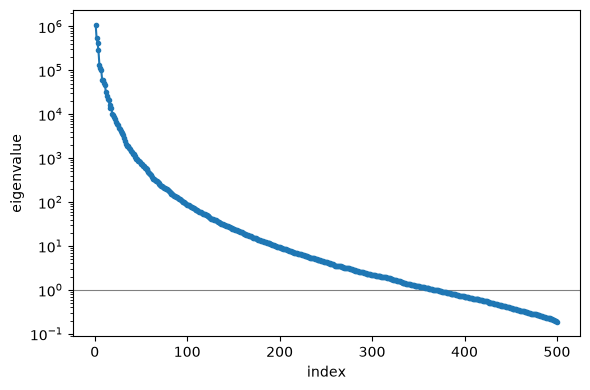

In [11]:
fig, axis = plt.subplots(figsize=(6, 4))
axis.axhline(1.0, color="gray", linewidth=0.8)
axis.semilogy(np.arange(1, eigenvalues.size + 1), eigenvalues, marker=".")
axis.set_xlabel("index")
axis.set_ylabel("eigenvalue")
fig.tight_layout()

## Convergence in the rank

The reduction of the pointwise variance by the first $k$ eigenpairs, $\mathrm{diag}(V_k D_k V_k^T)$, is exact (no sampling), and the log-determinant ratio $-\sum_{i \le k} \log(1 + \lambda_i)$ is the information gained about the prior. Both are plotted against $k$: curves that are still rising at the full rank mean that more eigenpairs would reduce the variance further.

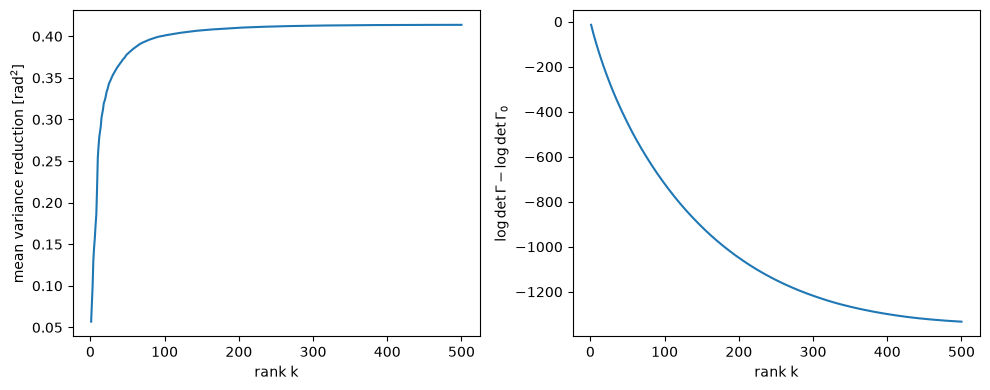

In [12]:
weights = eigenvalues / (1.0 + eigenvalues)
ranks = np.arange(1, eigenvalues.size + 1)
mean_variance_reduction = np.cumsum(np.mean(eigenvectors**2, axis=0) * weights)
log_determinant_ratio = -np.cumsum(np.log1p(eigenvalues))

fig, (reduction_axis, determinant_axis) = plt.subplots(1, 2, figsize=(10, 4))
reduction_axis.plot(ranks, mean_variance_reduction)
reduction_axis.set_xlabel("rank k")
reduction_axis.set_ylabel("mean variance reduction [rad$^2$]")
determinant_axis.plot(ranks, log_determinant_ratio)
determinant_axis.set_xlabel("rank k")
determinant_axis.set_ylabel(r"$\log\det\Gamma - \log\det\Gamma_0$")
fig.tight_layout()

## Samples, pointwise variance and axial statistics

Samples of the approximation are $m_\mathrm{MAP} + \hat\Gamma \xi$ with $\xi$ standard normal. Their variance per vertex is the diagonal of $\Gamma$ up to a relative sampling error of about $\sqrt{2/N}$ (the Rademacher probing estimate of `LowRankGaussian.compute_pointwise_variance` is far too noisy for the small prior variance here). The angles are not wrapped, so this variance is that of the Gaussian marginals. The axial mean and variance (`compute_axial_mean_and_variance`) are those of the MCMC run, so they can be compared with it below.

In [13]:
NUM_SAMPLES = 1000

samples = np.stack([approximation.gaussian.generate_sample() for _ in range(NUM_SAMPLES)])
laplace_variance = samples.var(axis=0, ddof=1)
laplace_axial_mean, laplace_axial_variance = compute_axial_mean_and_variance(samples)
laplace_std = compute_standard_deviation_degrees(laplace_variance)
laplace_axial_std = compute_standard_deviation_degrees(laplace_axial_variance)

print(f"pointwise std: mean {laplace_std.mean():.2f}, max {laplace_std.max():.2f} deg")
print(f"axial std:     mean {laplace_axial_std.mean():.2f}, max {laplace_axial_std.max():.2f} deg")

pointwise std: mean 4.89, max 17.64 deg
axial std:     mean 4.89, max 17.62 deg


## Posterior standard deviation

Pointwise standard deviation of the angle, in degrees.

In [14]:
plot_mesh = mesh.copy()
plot_mesh.point_data["std"] = laplace_std
plotter = pv.Plotter()
plotter.add_mesh(plot_mesh, scalars="std", cmap="viridis")
plotter.add_text("Laplace pointwise standard deviation [deg]")
plotter.show()

Widget(value='<iframe src="http://localhost:33681/index.html?ui=P_0x7f4b487c2c10_1&reconnect=auto" class="pyvi…

## Standard deviation vs. distance to the observations

Away from the data the prior decides, so the standard deviation should grow with the distance to the nearest observation (shortest path along mesh edges, `compute_graph_distances`) towards the prior standard deviation. The plot shows the median and the 90th percentile in bins with equally many vertices.

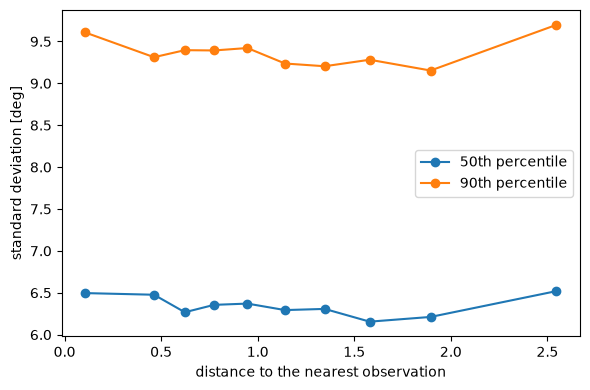

In [9]:
vertex_distances = compute_graph_distances(
    assemble_edge_length_graph(mesh.points, connectivity),
    data.observed_vertex_indices,
    min_over_sources=True,
)
distance_quantiles = (0.5, 0.9)
bin_distances, bin_quantiles = compute_error_by_distance(
    vertex_distances, laplace_std, num_bins=10, quantiles=distance_quantiles
)

fig, axis = plt.subplots(figsize=(6, 4))
for quantile, values in zip(distance_quantiles, bin_quantiles.T, strict=True):
    axis.plot(bin_distances, values, marker="o", label=f"{int(100 * quantile)}th percentile")
axis.set_xlabel("distance to the nearest observation")
axis.set_ylabel("standard deviation [deg]")
axis.legend()
fig.tight_layout()

## Comparison with MCMC

If the chain of `pixi run example-mcmc` is available (it is not git-tracked), its axial standard deviation after the burn-in is compared with the one of the Laplace samples, vertex by vertex. The Laplace approximation is centered at the MAP estimate and Gaussian, the chain explores the actual posterior, so the two agree only where the posterior is close to Gaussian and the chain has converged; the short example chain has not explored far from its start at the MAP estimate, so it tends to underestimate the spread.

In [ ]:
BURN_IN = 100
mcmc_store_path = MCMC_DIR / "samples.zarr"

if mcmc_store_path.exists():
    chain = zarr.open_group(mcmc_store_path, mode="r")["data"]
    _, mcmc_axial_variance = compute_axial_mean_and_variance(
        chain, burn_in=BURN_IN, block_size=chain.chunks[0]
    )
    mcmc_axial_std = compute_standard_deviation_degrees(mcmc_axial_variance)
    print(
        f"mean axial std: Laplace {laplace_axial_std.mean():.2f}, "
        f"MCMC {mcmc_axial_std.mean():.2f} deg"
    )

    fig, axis = plt.subplots(figsize=(5, 5))
    axis.scatter(mcmc_axial_std, laplace_axial_std, s=2, alpha=0.3)
    limit = max(mcmc_axial_std.max(), laplace_axial_std.max())
    axis.plot([0, limit], [0, limit], color="gray", linewidth=0.8)
    axis.set_xlabel("MCMC axial standard deviation [deg]")
    axis.set_ylabel("Laplace axial standard deviation [deg]")
    fig.tight_layout()
else:
    print(f"no chain at {mcmc_store_path}; run `pixi run example-mcmc` to compare")